In [1]:
import os

import networkx as nx
import pandas as pd
from biotite.database import uniprot
from tqdm import tqdm

In [2]:
from philharmonic.utils import (
    calculate_graph_triangles,
    load_cluster_json,
    nx_graph_cluster,
    parse_GO_database,
    parse_GO_map,
    plot_degree,
    write_cluster_cytoscape,
)

In [3]:
all_protein_file = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/afdb_download/pdam_protein_list.txt"
all_proteins = [line.strip() for line in open(all_protein_file).readlines()]

failed_proteins_file = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/afdb_download/FAILED_PROTEINS.txt"
failed_proteins = [
    line.strip().split()[0]
    for line in open(failed_proteins_file).readlines()
    if line.startswith("pdam")
]

foldseek_result_file = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/afdb_download/pdam_foldseek_afdb_proteome.m8"
foldseek_results = pd.read_csv(
    foldseek_result_file,
    sep="\t",
    header=None,
    names=[
        "query",
        "target",
        "pident",
        "alnlen",
        "mismatch",
        "gapopen",
        "qstart",
        "qend",
        "tstart",
        "tend",
        "evalue",
        "bitscore",
    ],
)

In [4]:
foldseek_results.head()

,query,target,pident,alnlen,mismatch,gapopen,qstart,qend,tstart,tend,evalue,bitscore
0,A0A3M6UY72,AF-Q6P7B2-F1-model_v6,0.109,320,259,0,78,369,3,322,0.2992,35
1,A0A3M6UY72,AF-K7LIY3-F1-model_v6,0.126,274,229,0,138,411,38,300,2.5050,33
2,A0A3M6UY72,AF-A4HXD5-F1-model_v6,0.133,385,299,0,23,368,30,414,0.2722,32
3,A0A3M6UY72,AF-O75509-F1-model_v6,0.133,211,181,0,222,431,439,649,3.1720,31
4,A0A3M6UY72,AF-Q10410-F1-model_v6,0.126,379,273,0,59,371,5,383,0.6075,28


In [5]:
def query_uniprot_for_id(pdam_id: str):
    """
    Query UniProt to find the UniProt accession for a pdam protein ID.

    Tries two strategies:
    1. Search for the pdam ID as a gene/protein name
    2. Search within P. damicornis organism with the pdam ID

    Returns:
        UniProt accession if found, None otherwise
    """
    # Strategy 1: Direct search for pdam ID
    query1 = f"(gene:{pdam_id}) OR (protein_name:{pdam_id})"
    try:
        results = uniprot.search(query1, number=1)
        if results:
            return results[0]
    except Exception:
        pass  # Try next strategy

    # Strategy 2: Organism-specific search
    query2 = f'(organism_name:" Pocillopora damicornis") AND ((gene:{pdam_id}) OR (protein_name:{pdam_id}))'
    try:
        results = uniprot.search(query2, number=1)
        if results:
            return results[0]
    except Exception:
        pass

    return None


up_mapping_file = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/afdb_download/pdam_to_uniprot_mapping.txt"
if not os.path.exists(up_mapping_file):
    pdam_to_uniprot = {
        pdam_id: query_uniprot_for_id(pdam_id) for pdam_id in tqdm(all_proteins)
    }

    with open(up_mapping_file, "w+") as f:
        for pdam_id, uniprot_id in pdam_to_uniprot.items():
            f.write(f"{pdam_id}\t{uniprot_id}\n")
else:
    pdam_to_uniprot = {}
    with open(up_mapping_file) as f:
        for line in f:
            pdam_id, uniprot_id = line.strip().split("\t")
            pdam_to_uniprot[pdam_id] = uniprot_id if uniprot_id != "None" else None
uniprot_to_pdam = {
    uniprot_id: pdam_id
    for pdam_id, uniprot_id in pdam_to_uniprot.items()
    if uniprot_id is not None
}

In [6]:
k = 5e-5
sig = foldseek_results[foldseek_results["evalue"] < k]["query"]
no_hits = foldseek_results[~foldseek_results["query"].isin(sig)]["query"].unique()

In [20]:
# Initial Files
# cluster_file_path = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/20240917-pdamAll-phil_v0.3.0/20240917-pdamAll-phil_v0.3.0_clusters.llm.json"
cluster_file_path = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/20240917-pdamAll-phil_v0.3.0/pdam_clusters.llm.json"
network_file_path = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/20240917-pdamAll-phil_v0.3.0/20240917-pdamAll-phil_v0.3.0_network.positive.tsv"
go_map_path = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/20240917-pdamAll-phil_v0.3.0/20240917-pdamAll-phil_v0.3.0_GO_map.csv"

GO_DB = "/mnt/home/ssledzieski/Projects/philharmonic-experiments/results/p_damicornis/20240917-pdamAll-phil_v0.3.0/go.obo"

In [21]:
cluster_dict = load_cluster_json(cluster_file_path)
go_database = parse_GO_database(GO_DB)
go_map = parse_GO_map(go_map_path)
full_G = nx.read_weighted_edgelist(network_file_path, delimiter="\t")
cluster_proteins = set.union(*[set(i["members"]) for i in cluster_dict.values()])

In [22]:
# proteins that don't have significant foldseek hits
no_hits_in_clusters = [
    f"{uniprot_to_pdam[p]}-RA"
    for p in no_hits
    if f"{uniprot_to_pdam[p]}-RA" in cluster_proteins
]

# find all clusters that have at least one member without hits
no_hit_clusters = [
    c
    for c in cluster_dict.values()
    if any(m in no_hits_in_clusters for m in c["members"])
]

# a cluster is interesting if it has between 3 and 30 members and at least 10 edges and at least 5 triangle, but is not too dense (number of edges < number of members**2 / 5)
no_hit_interesting_clusters = [
    c
    for c in no_hit_clusters
    if 3 <= len(c["members"]) <= 30
    and full_G.subgraph(c["members"]).number_of_edges() >= 10
    and calculate_graph_triangles(full_G.subgraph(c["members"])) >= 5
    and full_G.subgraph(c["members"]).number_of_edges() < len(c["members"]) ** 2 / 5
]

In [23]:
len(no_hit_interesting_clusters)

43

In [24]:
for c in no_hit_interesting_clusters:
    print(c["human_readable"])
    print("---")

Cluster Name: Cerebellar Development and Cell Cycle Regulation
Cluster of 28 proteins [pdam_00018973-RA, pdam_00011383-RA, pdam_00023698-RA, ...] (hash 744582039424568290)
0 proteins re-added by ReCIPE (degree, 0.75)
Edges: 37
Triangles: 16
Max Degree: 18
Top Terms:
		GO:0021697 - <cerebellar cortex formation> (25)
		GO:0045736 - <negative regulation of cyclin-dependent protein serine/threonine kinase activity> (25)
		GO:2001275 - <obsolete positive regulation of glucose import in response to insulin stimulus> (25)
		GO:0008286 - <insulin receptor signaling pathway> (25)
		GO:0034501 - <protein localization to kinetochore> (25)
		GO:0000082 - <G1/S transition of mitotic cell cycle> (25)
		GO:0060020 - <Bergmann glial cell differentiation> (25)
		GO:0008285 - <negative regulation of cell population proliferation> (25)
		GO:0050852 - <T cell receptor signaling pathway> (25)
		GO:0048679 - <regulation of axon regeneration> (25)
LLM Explanation: This cluster is strongly associated with cer

In [25]:
# key = "380741951891672132"
# key = "692645375291424142"
# key = "889733293002804025"
# key = "1752595303340288550"
# key = "2067603048326687333"
key = "1337569685223779389"

print(cluster_dict[key]["human_readable"])

for i in cluster_dict[key]["members"]:
    if pdam_to_uniprot[i.split("-")[0]] in no_hits:
        print(i)

Cluster Name: Temperature and Pain Regulation
Cluster of 16 proteins [pdam_00019213-RA, pdam_00022320-RA, pdam_00010075-RA, ...] (hash 1337569685223779389)
0 proteins re-added by ReCIPE (degree, 0.75)
Edges: 20
Triangles: 5
Max Degree: 6
Top Terms:
		GO:0071502 - <cellular response to temperature stimulus> (14)
		GO:0019233 - <sensory perception of pain> (14)
		GO:0002024 - <diet induced thermogenesis> (14)
		GO:0030168 - <platelet activation> (11)
		GO:0002032 - <obsolete desensitization of G protein-coupled receptor signaling pathway by arrestin> (11)
		GO:0022400 - <regulation of opsin-mediated signaling pathway> (11)
		GO:0051586 - <positive regulation of dopamine uptake involved in synaptic transmission> (11)
		GO:0031635 - <adenylate cyclase-inhibiting opioid receptor signaling pathway> (11)
		GO:2000479 - <regulation of cAMP-dependent protein kinase activity> (11)
		GO:0040015 - <negative regulation of multicellular organism growth> (11)
LLM Explanation: This cluster includes a 

In [194]:
pdam_to_uniprot["pdam_00002663"], pdam_to_uniprot["pdam_00003116"]

('A0A3M6U374', 'A0A3M6T9Q0')

In [30]:
go_term = "GO:0071502"
temp_stim_binary = []

for i in cluster_dict[key]["members"]:
    print(i, go_term in go_map[i])
    temp_stim_binary.append((i, go_term in go_map[i]))
with open(f"cytocscape_table_{key}_{go_term}.txt", "w+") as f:
    for i, j in temp_stim_binary:
        f.write(f"{i}\t{j}\n")

pdam_00019213-RA True
pdam_00022320-RA True
pdam_00010075-RA False
pdam_00002663-RA True
pdam_00006946-RA True
pdam_00011108-RA True
pdam_00008011-RA True
pdam_00021662-RA True
pdam_00002742-RA True
pdam_00002659-RA True
pdam_00017022-RA True
pdam_00001658-RA True
pdam_00003116-RA False
pdam_00016972-RA True
pdam_00001766-RA True
pdam_00002990-RA True


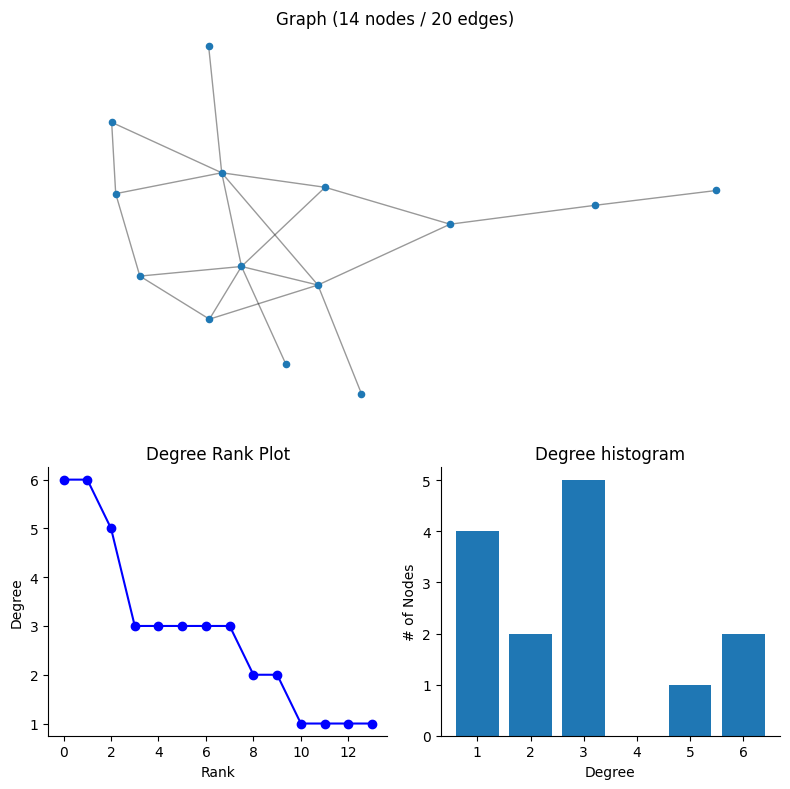

In [13]:
plot_degree(nx_graph_cluster(cluster_dict[key], full_G))

In [14]:
write_cluster_cytoscape(cluster_dict[key], full_G, f"cytoscape_input_{key}")